# Tools：工具定义与调用


## 为什么模型需要工具？

模型可以解释“怎样查天气”，但实时天气需要从外部服务获取；模型可以写计算过程，但准确计算可以交给程序。工具把模型的语言理解能力与外部数据、确定性计算和业务操作连接起来。

| 场景 | 工具负责什么 | 模型负责什么 |
| --- | --- | --- |
| 查询天气、新闻 | 获取外部数据 | 判断需要什么信息，组织回答 |
| 数学计算 | 按程序规则计算 | 识别问题、选择计算工具 |
| 数据库查询 | 按权限读取业务数据 | 提取查询意图、解释结果 |
| 邮件、日历操作 | 执行具体操作 | 理解任务、生成所需参数 |

第 04 章介绍了 `AIMessage.tool_calls` 与 `ToolMessage`，这一章继续讲：**工具如何定义，模型怎样请求调用，应用怎样执行并回传结果。**

本篇根据尚硅谷第 05 章的 44 页课件整理。所有代码只作阅读示例，放在 Markdown 代码块中；天气、股票和新闻示例中的固定数据都是模拟数据。

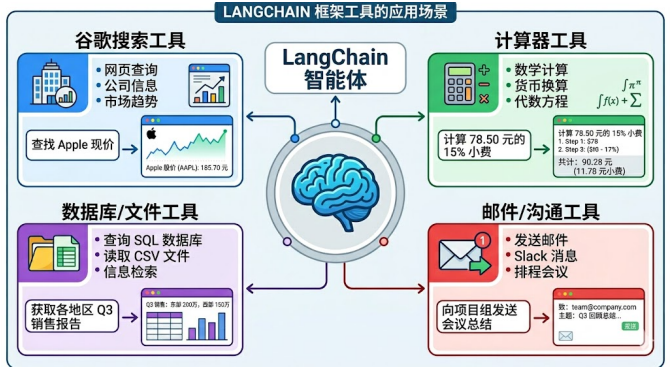

课件图示：搜索、计算、数据库与通信工具的应用场景。


## 一个工具有两部分：说明与实现

在本章的函数工具场景中，Tool 是有明确输入结构的可调用对象。它包括：

| 部分 | 内容 | 谁使用它 |
| --- | --- | --- |
| 工具描述 | 名称、用途、参数类型、必填字段等 | 模型据此选择工具并生成参数 |
| 工具实现 | Python 函数或其他实际执行逻辑 | 应用运行它，得到结果 |

例如 `get_weather(city: str)`：模型接收“按城市查询天气”的描述，返回 `city="北京"` 的调用请求；真正获取天气的是应用中的函数。

**绑定工具通常向模型提交的是工具描述，而不是让模型远程执行本地 Python 函数。** 所以只调用 `bind_tools()` 和模型的 `invoke()`，还没有完成工具执行。


## 完整流程：请求工具、执行工具、回传结果

课件中的经典流程可以归为四步：

1. 定义工具，通过 `model.bind_tools([...])` 把描述交给模型。
2. 调用模型，得到 `AIMessage`；其中可能有 `tool_calls`。
3. 应用读取工具名称和参数，执行对应工具。
4. 将 AI 的调用请求和 `ToolMessage` 一起保存，再让模型生成回答或继续请求工具。

~~~text
HumanMessage：北京天气如何？
    ↓ 模型推理
AIMessage.tool_calls：get_weather(city="北京"), id="call_001"
    ↓ 应用执行函数
ToolMessage：北京晴天（模拟数据），tool_call_id="call_001"
    ↓ 模型读取工具结果
AIMessage：基于查询结果组织回答
~~~

模型也可能直接回答，或在一条 AIMessage 中请求多个工具。多个结果返回后，还可能继续请求下一批工具，所以一般要用循环管理整个过程。

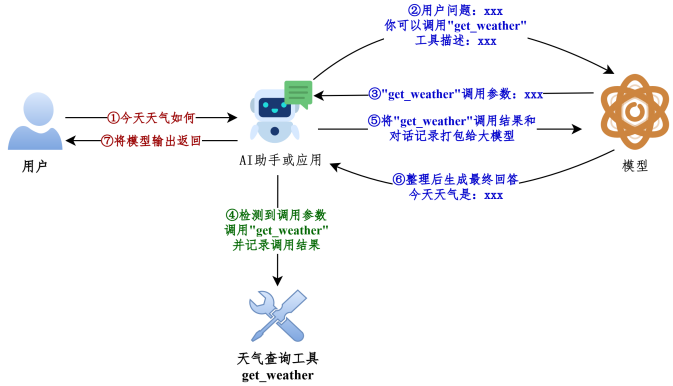

课件图示：应用连接用户、模型与工具，并负责执行工具。


## 本章示例的公共配置

定义工具、查看 Schema、直接调用本地模拟工具都不需要模型密钥。出现 `model.invoke()` 时，使用本节的 `model`，或沿用第 02、04 章已配置的聊天模型。

按课件的 OpenAI 兼容服务方式配置依赖：

~~~bash
uv add langchain langchain-openai python-dotenv pydantic
~~~

`.env` 示例：

~~~dotenv
CLOSEAI_API_KEY=你的模型服务密钥
CLOSEAI_BASE_URL=服务商提供的OpenAI兼容API地址
CHAT_MODEL=支持工具调用且账户可用的模型名称
~~~

~~~python
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

load_dotenv()
model = init_chat_model(
    model=os.environ["CHAT_MODEL"],
    model_provider="openai",
    api_key=os.environ["CLOSEAI_API_KEY"],
    base_url=os.environ["CLOSEAI_BASE_URL"],
)
~~~

兼容聊天接口不等于支持所有工具调用参数。换模型或服务商后，要核对 Tool Calling、`tool_choice` 及对应集成的支持范围。


## 定义方式一：普通 Python 函数

课件先用普通函数演示工具描述的生成。对于支持相应转换的模型集成，带类型注解和说明的函数可以直接传入 `bind_tools()`。

~~~python
def get_weather_plain(city: str) -> str:
    """按城市名称查询当日天气；本函数返回模拟数据。"""
    return f"{city}：晴天，15°C（模拟数据）。"

bound_model = model.bind_tools([get_weather_plain])
ai_message = bound_model.invoke("北京天气如何？")

print(ai_message.tool_calls)
~~~

普通函数仍按 Python 的方式执行：

~~~python
result = get_weather_plain(city="北京")
~~~

它不会因为传给 `bind_tools()` 就自动拥有 `.invoke()`。普通函数的输入约束也不会仅凭类型注解就在 Python 调用时自动校验。


## 查看工具描述：convert_to_openai_tool

`convert_to_openai_tool()` 把函数或工具对象转换成 OpenAI 风格的工具描述，适合学习 Schema 与排查参数。其他模型集成最终发送的格式可能不同。

~~~python
import json
from langchain_core.utils.function_calling import convert_to_openai_tool

schema = convert_to_openai_tool(get_weather_plain)
print(json.dumps(schema, ensure_ascii=False, indent=2))
~~~

下面是省略版本相关附加字段后的核心结构：

~~~json
{
  "type": "function",
  "function": {
    "name": "get_weather_plain",
    "description": "按城市名称查询当日天气；本函数返回模拟数据。",
    "parameters": {
      "type": "object",
      "properties": {
        "city": {"type": "string"}
      },
      "required": ["city"]
    }
  }
}
~~~

| 字段 | 作用 |
| --- | --- |
| 最外层 `type="function"` | 说明这是函数类型的工具 |
| `function.name` | 模型返回调用请求时使用的工具名称 |
| `function.description` | 工具用途与使用条件 |
| `parameters.type="object"` | 参数整体是一组键值数据 |
| `properties` | 每个参数的类型、说明或限制 |
| `required` | 必须提供的参数名 |

最外层的工具类型与参数内部的 JSON Schema 类型处在不同层级，不要混淆。


## 类型注解、默认值与必填参数

参数 Schema 通常从函数签名提取：类型注解说明类型，默认值影响参数是否必填。

~~~python
from langchain_core.utils.function_calling import convert_to_openai_tool

def weather_on_date(date: str, city: str = "北京") -> str:
    """返回指定日期与城市的模拟天气。"""
    return f"{city}，{date}：晴天（模拟数据）。"

schema = convert_to_openai_tool(weather_on_date)
parameters = schema["function"]["parameters"]
print(parameters)
~~~

通常 `date` 出现在 `required` 中，`city` 包含默认值且不必填。没有类型注解时，转换结果可能缺少明确的类型，或在解析文档时产生错误，因此要把类型写完整。

注意三个层次：**Schema 描述参数，模型生成参数，应用校验并执行参数。** 在 Schema 中写一个 `default` 不代表 JSON Schema 自己会替函数补值；运行时默认值仍应与函数签名、校验逻辑保持一致。供应商的严格 Schema 模式也可能对默认值和必填规则提出额外要求。


## 定义方式二：用 @tool 包装函数

`@tool` 把函数转换成 LangChain 工具对象，提供名称、描述、输入 Schema、`invoke()` / `ainvoke()` 等能力，是课件推荐的常用写法。

~~~python
from langchain_core.tools import tool

@tool
def get_weather(city: str) -> str:
    """获取指定城市的当日天气；返回模拟数据。"""
    return f"{city}：晴天，15°C（模拟数据）。"

print(get_weather.name)
print(get_weather.description)
print(get_weather.args)
print(get_weather.invoke({"city": "北京"}))
~~~

装饰后，变量 `get_weather` 指向工具对象，不再是原来的普通函数。学习时使用 `.invoke()`，不要继续把它当成普通函数直接写 `get_weather(city="北京")`。

不显式提供描述时，通常需要函数 docstring。简单的一句话说明就可以，并不是所有 `@tool` 都必须写完整 Google 风格文档。


## description：告诉模型何时使用工具

清楚的描述要说明工具获取什么信息、输入是什么，以及必要的使用边界。“处理数据”“做一些事情”不能帮助模型可靠选择工具。

~~~python
from langchain_core.tools import tool

@tool(description="根据城市名称获取当日天气；这是模拟工具，不查询真实天气服务。")
def weather_demo(city: str) -> str:
    """天气演示函数。"""
    return f"{city}：晴天（模拟数据）。"
~~~

显式的 `description` 优先于函数文档中的工具整体说明。它与参数说明不同：整体描述用于选工具，参数描述用于生成正确的输入。

模型读取的是发送出去的描述与 Schema，不会仅凭函数内部实现自动了解业务逻辑。工具描述写成实时查询，内部却返回固定文字，会让模型对结果来源产生错误判断。


## parse_docstring：把参数说明提取到 Schema

普通 `@tool` 默认通常把 docstring 作为整体说明。需要将 `Args:` 中的文字提取为各参数的 `description`，可以启用 `parse_docstring=True`。

~~~python
from langchain_core.tools import tool
from langchain_core.utils.function_calling import convert_to_openai_tool

@tool(parse_docstring=True)
def weather_with_docs(
    city: str,
    unit: str = "celsius",
    include_forecast: bool = False,
) -> str:
    """返回当日天气，可附带未来五日预报；数据为模拟值。

    Args:
        city: 城市名称，例如北京或上海。
        unit: 温度单位，celsius 表示摄氏度，fahrenheit 表示华氏度。
        include_forecast: 是否附带未来五日预报。
    """
    if unit not in {"celsius", "fahrenheit"}:
        raise ValueError("不支持的温度单位")
    temperature = 22 if unit == "celsius" else 71.6
    result = f"{city}：{temperature} {unit}（模拟数据）"
    if include_forecast:
        result += "；未来五日晴天（模拟数据）"
    return result

print(convert_to_openai_tool(weather_with_docs))
~~~

采用 Google 风格：简短说明与 `Args:` 之间留空行，各参数名与函数签名一致，并正确缩进。启用解析后，格式不合法或参数名不匹配可能抛出 `ValueError`；不能笼统理解为“所有带 @tool 的 docstring 格式不合规范都会报错”。

参数说明中写“只能取两个值”仍主要是文字提示。真正的枚举校验可以用 `Literal`、Pydantic 或函数内的检查。


## 自定义名称：模型用工具名，Python 用变量名

默认工具名称来自函数名。需要更清楚的公开名称时，可以在装饰器中指定：

~~~python
from langchain_core.tools import tool

@tool("get_weather_and_forecast")
def weather_impl(city: str, include_forecast: bool = False) -> str:
    """返回当日天气与可选预报；使用模拟数据。"""
    result = f"{city}：今天晴天（模拟数据）"
    if include_forecast:
        result += "；明天有雨（模拟数据）"
    return result

print(weather_impl.name)  # get_weather_and_forecast
tools_by_name = {weather_impl.name: weather_impl}
~~~

模型返回的是公开名称 `get_weather_and_forecast`；应用里的变量仍是 `weather_impl`。分发时按 `.name` 建表，避免手工写错函数名与工具名的对应关系。

课程提醒不要把 `config`、`runtime` 随意当成业务参数。这些名称涉及框架配置或运行时注入；本章用 `city`、`unit` 等明确的业务名称即可，运行时上下文在后续章节学习。


## tool.invoke 的输入不同，返回值也可能不同

用 `@tool` 定义的普通内容工具，直接传参数字典时，返回工具的业务结果；传入包含调用 ID 的完整 ToolCall 时，通常返回包装好的 `ToolMessage`。

~~~python
from langchain_core.tools import tool

@tool
def weather_for_invoke(city: str) -> str:
    """返回城市天气的模拟文本。"""
    return f"{city}：晴天（模拟数据）。"

raw_result = weather_for_invoke.invoke({"city": "北京"})

call = {
    "name": weather_for_invoke.name,
    "args": {"city": "北京"},
    "id": "call_weather_001",
    "type": "tool_call",
}
tool_message = weather_for_invoke.invoke(call)

print(type(raw_result).__name__)    # str
print(type(tool_message).__name__)  # ToolMessage
print(tool_message.tool_call_id)   # call_weather_001
~~~

| 输入 | 本例返回 | 用途 |
| --- | --- | --- |
| `{"city": "北京"}` | 业务结果字符串 | 本地调试、直接调用 |
| 完整 `ToolCall` | `ToolMessage` | 执行模型生成的请求并回传 |

如果只传 `call["args"]`，就要手动构造 ToolMessage 并设置 `tool_call_id`。不是每次 `.invoke()` 都自动返回 ToolMessage，关键是是否传了完整调用结构。


## 用普通函数完成一次工具调用

使用前面的 `get_weather_plain` 与公共 `model`，应用自己分发函数并包装结果：

~~~python
from langchain_core.messages import HumanMessage, ToolMessage

bound_model = model.bind_tools([get_weather_plain])
messages = [HumanMessage(content="北京天气如何？")]
ai_message = bound_model.invoke(messages)
messages.append(ai_message)

for call in ai_message.tool_calls:
    if call["name"] != "get_weather_plain":
        raise ValueError("请求了未注册的工具")
    result = get_weather_plain(**call["args"])
    messages.append(ToolMessage(
        content=result,
        name=call["name"],
        tool_call_id=call["id"],
    ))

if ai_message.tool_calls:
    answer = model.invoke(messages)
else:
    answer = ai_message

print(answer.content)
~~~

最后用未绑定工具的 `model` 汇总结果，适合确定的一次工具阶段。需要模型根据结果继续选工具时，要继续调用绑定后的模型并用循环管理。

必须保存请求工具的 AIMessage，不能只把用户消息和 ToolMessage 传回模型，否则工具结果缺少对应的请求。


## 用 @tool 完成同样的消息流转

使用本章已定义的 `get_weather` 工具，可以直接把完整 ToolCall 交给工具：

~~~python
from langchain_core.messages import HumanMessage

bound_model = model.bind_tools([get_weather])
tools_by_name = {get_weather.name: get_weather}
messages = [HumanMessage(content="北京天气如何？")]

ai_message = bound_model.invoke(messages)
messages.append(ai_message)

for call in ai_message.tool_calls:
    selected_tool = tools_by_name[call["name"]]
    messages.append(selected_tool.invoke(call))

answer = model.invoke(messages) if ai_message.tool_calls else ai_message
if ai_message.tool_calls:
    messages.append(answer)

for message in messages:
    message.pretty_print()
~~~

这里减少的是手动包装 ToolMessage 的代码。选择工具、执行工具、保存消息、再次调用模型这些职责仍然存在。

一条 AIMessage 请求多个工具时，应为每个调用生成匹配的结果。等这一批工具结果完整返回后，再进行下一次模型调用。


## Pydantic：把参数结构与校验规则写清楚

参数较多，或需要枚举与范围约束时，Pydantic 比单靠文字说明更清晰。本章使用 Pydantic 2 风格。

~~~python
from typing import Literal
from pydantic import BaseModel, Field

class WeatherInput(BaseModel):
    city: str = Field(default="北京", min_length=1, description="城市名称")
    unit: Literal["celsius", "fahrenheit"] = Field(
        default="celsius", description="温度单位"
    )
    include_forecast: bool = Field(
        default=False, description="是否包含未来五日预报"
    )

data = WeatherInput(city="杭州", unit="celsius", include_forecast=True)
print(data.model_dump())
print(WeatherInput.model_json_schema())
~~~

| 写法 | 用途 |
| --- | --- |
| 继承 `BaseModel` | 定义数据模型 |
| 类型注解 | 定义字段类型 |
| `Field(description=...)` | 给模型看的字段说明 |
| `Field(default=...)` | 默认值 |
| `Literal[...]` | 限制允许的固定选项 |
| `Field(ge=..., le=...)` 等 | 数值范围约束 |
| `model_dump()` | 把校验后的对象转为字典 |
| `model_json_schema()` | 生成 JSON Schema 描述 |

字段使用关键字传入，例如 `WeatherInput(city="杭州")`，不是 `WeatherInput("杭州")`。Pydantic 默认可能做类型转换；需要禁止转换时，再选择严格校验规则。


## args_schema：把 Pydantic 模型绑定到工具

工具的 `args_schema` 使用 Pydantic 类，既描述参数，也在工具执行入口参与校验。不是在模型推理内部运行 Python 校验。

~~~python
from langchain_core.tools import tool

@tool(args_schema=WeatherInput)
def weather_with_schema(
    city: str = "北京",
    unit: str = "celsius",
    include_forecast: bool = False,
) -> str:
    """返回当日天气，可选未来五日预报；数据为模拟值。"""
    temperature = 22 if unit == "celsius" else 71.6
    result = f"{city}：{temperature} {unit}（模拟数据）"
    if include_forecast:
        result += "；未来五日晴天（模拟数据）"
    return result

result = weather_with_schema.invoke({"city": "杭州", "include_forecast": True})
print(result)
~~~

Schema 的字段名要与函数参数名一致，默认值也要保持一致。部分工具实现只把显式输入的字段传给函数，因此不要在 Schema 中把 `city` 设为可省略，却在函数签名中把它设为无默认值的必填参数。

课件中曾出现 `location` / `units` 与 `city` / `unit` 混用的示例。工具描述能打印出来，不代表执行一定成功；这里统一使用 `city`、`unit` 和 `include_forecast`。


### 参数非法时：校验错误发生在哪里？

下面是本地校验示例，`kelvin` 不属于允许的选项：

~~~python
from pydantic import ValidationError

try:
    weather_with_schema.invoke({"city": "杭州", "unit": "kelvin"})
except ValidationError as error:
    print("参数不合法：", error.errors()[0]["loc"])
~~~

校验不通过时，工具函数的业务逻辑通常还没有执行。模型生成了错误参数，不代表工具必须硬着头皮执行；应用可以把错误整理成 ToolMessage，让模型补充或修正参数。

也要区分“合法”与“真实”：`city` 是字符串且非空，只说明符合输入规则，不说明该城市存在，更不说明工具结果是真实天气。业务有效性仍需要实际查询与校验。


## 另一种 args_schema：直接提供 JSON Schema 字典

参数结构需要动态生成时，可以直接使用 JSON Schema 字典。传给 `args_schema` 的是参数对象本身，不是带 `type="function"` 的完整工具描述，也不是 JSON 字符串。

~~~python
from langchain_core.tools import tool

weather_schema = {
    "type": "object",
    "properties": {
        "city": {"type": "string", "description": "城市名称"},
        "unit": {
            "type": "string",
            "enum": ["celsius", "fahrenheit"],
            "default": "celsius",
            "description": "温度单位",
        },
        "include_forecast": {
            "type": "boolean", "default": False,
            "description": "是否包含未来五日预报",
        },
    },
    "required": ["city"],
}

@tool(args_schema=weather_schema)
def weather_with_json_schema(
    city: str, unit: str = "celsius", include_forecast: bool = False
) -> str:
    """返回城市天气；使用模拟数据。"""
    validated = WeatherInput(
        city=city, unit=unit, include_forecast=include_forecast
    )
    temperature = 22 if validated.unit == "celsius" else 71.6
    result = f"{validated.city}：{temperature} {validated.unit}（模拟数据）"
    if validated.include_forecast:
        result += "；未来五日晴天（模拟数据）"
    return result
~~~

JSON Schema 字典主要用于描述，不能假定 LangChain 对它提供与 Pydantic 类相同的本地校验或默认值填充。本例在函数入口显式使用 `WeatherInput` 校验，函数签名也提供运行时默认值。

固定的 Python 项目通常用 Pydantic 类更省事；动态 Schema 则需要同时维护描述、实际实现与校验逻辑。


## 课件天气案例：用 Schema 或 docstring 表达同一任务

“今天杭州天气如何？明天呢？”需要模型识别两个信息：`city="杭州"` 与 `include_forecast=True`。

| 方式 | 参数类型与默认值来自哪里 | 参数说明来自哪里 |
| --- | --- | --- |
| `@tool(parse_docstring=True)` | 函数签名 | Google 风格 docstring 的 Args |
| `@tool(args_schema=WeatherInput)` | Pydantic 字段，并与签名对齐 | Field 的 description |
| JSON Schema 字典 | 字典中的类型与规则，运行时另行处理 | properties 内的 description |

使用前面定义的 `weather_with_schema`，调用流程仍是一样的：

~~~python
from langchain_core.messages import HumanMessage

messages = [HumanMessage(content="今天杭州天气如何？未来五天呢？")]
bound_model = model.bind_tools([weather_with_schema])
ai_message = bound_model.invoke(messages)
messages.append(ai_message)

for call in ai_message.tool_calls:
    if call["name"] != weather_with_schema.name:
        raise ValueError("工具名称不匹配")
    messages.append(weather_with_schema.invoke(call))

answer = model.invoke(messages) if ai_message.tool_calls else ai_message
print(answer.content)
~~~

模型实际生成的参数需要查看 `tool_calls`，不能只根据最终回答判断调用对不对。先看描述是否清楚，再看 Schema 是否正确，再看传入函数的参数。


## 多工具与多轮工具调用是两件事

课件展示了股票 + 新闻、天气 + 新闻两组工具。一次推理可以返回多个调用请求，也可以先调用一个工具，再根据其结果决定下一个工具。

~~~text
同一批多个调用：
Human → AI[股票请求, 新闻请求] → Tool[股票结果] → Tool[新闻结果] → AI回答

跨轮继续调用：
Human → AI[工具A请求] → Tool[A结果] → AI[工具B请求] → Tool[B结果] → AI回答
~~~

`tool_calls` 是列表，要遍历全部调用；外层循环则负责判断是否需要继续推理。把一批工具逐个执行是串行执行，模型一次返回多个请求并不意味着本地函数已并行运行。

课件“每次运行调用一个工具”的说法与后面一次返回两个调用的日志不一致。准确说法是：**一次模型响应可能包含零个、一个或多个工具调用请求；执行与循环由应用管理。**


## 一个可复用的工具调用循环

下面使用本章的 `@tool` 工具，每次完整执行一批调用，再把结果传回模型。工具名称通过注册表分发，并设置模型推理次数上限。

~~~python
def run_tool_loop(model, tools, messages, max_steps=6):
    if max_steps < 1:
        raise ValueError("max_steps 至少为 1")
    tools_by_name = {item.name: item for item in tools}
    if len(tools_by_name) != len(tools):
        raise ValueError("工具名称不能重复")

    bound_model = model.bind_tools(tools)
    messages = list(messages)

    for _ in range(max_steps):
        ai_message = bound_model.invoke(messages)
        messages.append(ai_message)
        if ai_message.invalid_tool_calls:
            raise ValueError("模型返回了无法解析的工具调用")
        if not ai_message.tool_calls:
            return ai_message, messages

        for call in ai_message.tool_calls:
            selected_tool = tools_by_name.get(call["name"])
            if selected_tool is None:
                raise ValueError(f"未注册的工具：{call['name']}")
            tool_message = selected_tool.invoke(call)
            messages.append(tool_message)

    raise RuntimeError("达到模型推理次数上限，尚未得到最终回答")
~~~

`max_steps` 统计模型推理次数，不是工具执行次数；一轮可能执行多个工具。达到上限时不能把最后一次工具请求当成最终答案返回。

这是基础循环：未知工具、参数错误或业务异常会中止。后面的失败处理小节说明怎样把可恢复错误交给模型，避免静默跳过某个调用导致消息配对不完整。


## 课件案例：股票查询与新闻搜索

先定义两个只返回模拟内容的工具。股票的时间范围用 `Literal` 表达，新闻正文明确标注为虚构教学内容。

~~~python
from typing import Literal
from langchain_core.tools import tool

@tool(parse_docstring=True)
def get_stock_price(
    company: str, timeframe: Literal["today", "week", "month"] = "today"
) -> str:
    """获取公司的股票价格模拟值，不查询实时行情。

    Args:
        company: 公司名称，例如苹果公司或微软公司。
        timeframe: 时间范围，today 为今日，week 为本周，month 为本月。
    """
    prices = {
        "苹果公司": {"today": 185.20, "week": 183.50, "month": 180.75},
        "微软公司": {"today": 415.86, "week": 412.30, "month": 405.42},
    }
    if company not in prices:
        return f"模拟数据中没有 {company} 的行情。"
    return f"{company} {timeframe}：{prices[company][timeframe]} 美元（模拟数据）。"

@tool(parse_docstring=True)
def search_news(company: str) -> str:
    """返回公司新闻的虚构教学示例，不搜索真实新闻。

    Args:
        company: 公司名称。
    """
    return f"{company}：示例新闻 A、示例新闻 B（均为虚构教学内容）。"
~~~

调用上一节的循环：

~~~python
from langchain_core.messages import HumanMessage, SystemMessage

messages = [
    SystemMessage(content="请查询工具，保留数据的模拟或虚构标记。"),
    HumanMessage(content="苹果公司今日模拟股价是多少？有哪些新闻示例？"),
]
answer, history = run_tool_loop(model, [get_stock_price, search_news], messages)
print(answer.content)
~~~

模型可能一次请求两个工具，也可能分两轮请求。应用都使用同一个循环。工具返回固定数据时，最终答案不能宣称“基于实时查询”；课件日志中的公司新闻与股价仅用于展示流程。


## 课件案例：天气与无参数新闻工具

工具也可以没有业务参数，此时模型的调用参数通常是空对象 `{}`。

~~~python
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage

@tool
def get_daily_news() -> str:
    """返回当日新闻的虚构教学示例，不查询真实新闻。"""
    return "示例新闻：某城市开展社区读书活动（虚构教学内容）。"

messages = [HumanMessage(content="展示杭州的模拟天气与新闻示例。")]
answer, history = run_tool_loop(model, [get_weather, get_daily_news], messages)

for message in history:
    message.pretty_print()
~~~

检查消息流时，应能找到用户问题、AI 的每个调用请求、对应 ToolMessage 与最终回答。多个工具结果各有 `tool_call_id`，不能把它们都写成同一个 ID。

固定需求知道一定需要两个数据源时，也可以由业务代码直接查询后交给模型总结；只有需要模型选择工具与参数时，才需要模型参与工具决策。


## tool_choice：控制模型是否请求工具

课件通过 `bind_tools(..., tool_choice=...)` 控制工具选择。以下是 OpenAI 兼容集成中常见的语义，具体支持范围由集成与服务商决定。

| 取值 | 含义 | 注意 |
| --- | --- | --- |
| `"none"` | 本次模型响应不请求工具 | 模型仍可能回答文本 |
| `"auto"` | 模型自行决定是否及如何请求工具 | 常用默认行为 |
| `"required"` | 必须请求至少一个工具 | 不代表所有工具都会调用 |
| `"any"` | 部分集成中映射为 required | 不保证所有供应商原生接受该值 |
| 工具名称字符串 | 强制请求指定工具 | 常见集成支持的简写 |
| 指定工具的结构化字典 | 明确指定函数工具 | 字典格式需与集成匹配 |

~~~python
no_tools = model.bind_tools([get_weather], tool_choice="none")
auto_tools = model.bind_tools([get_weather], tool_choice="auto")
required_tools = model.bind_tools([get_weather], tool_choice="required")

no_call_response = no_tools.invoke("北京天气如何？")
auto_response = auto_tools.invoke("你好。")
required_response = required_tools.invoke("北京天气如何？")
~~~

这些配置控制的是模型生成调用请求，仍不会执行工具。`required` 不保证参数业务正确；即便只说“你好”，模型也可能为了满足限制请求天气工具，所以不要把它当作提高回答质量的通用开关。


## 强制指定工具：使用公开名称

如果业务规定必须使用某个工具，可以指定它的公开名称。下面使用前面定义的 `weather_impl`，公开名称是 `get_weather_and_forecast`。

~~~python
forced_model = model.bind_tools(
    [weather_impl, get_weather],
    tool_choice=weather_impl.name,
)
ai_message = forced_model.invoke("杭州今天和明天的模拟天气如何？")
print(ai_message.tool_calls)
~~~

OpenAI 风格的结构化写法如下，是否可直接传入要看当前集成：

~~~python
forced_model = model.bind_tools(
    [weather_impl, get_weather],
    tool_choice={
        "type": "function",
        "function": {"name": weather_impl.name},
    },
)
~~~

强制指定工具时，用的是工具 `.name`，不是 Python 变量名。两个功能相同的工具若没有清楚的名称与说明，`auto` 也难以可靠选择；能合并成一个职责明确的工具时，不必保留多个重复工具。


## 强制工具之后，要允许模型完成回答

如果整个循环一直使用 `tool_choice="required"`，每次推理都被要求请求工具，即使已经拿到结果，也可能继续请求，无法自然输出最终答案。

需要“第一步必查工具”时，可以仅对第一次推理强制，后续恢复自动选择：

~~~python
from langchain_core.messages import HumanMessage

tools = [get_weather]
messages = [HumanMessage(content="北京的模拟天气如何？")]
first_model = model.bind_tools(tools, tool_choice="required")
first_response = first_model.invoke(messages)
messages.append(first_response)

if first_response.invalid_tool_calls or not first_response.tool_calls:
    raise ValueError("首次响应未返回有效的工具调用")

tools_by_name = {item.name: item for item in tools}
for call in first_response.tool_calls:
    messages.append(tools_by_name[call["name"]].invoke(call))

answer, history = run_tool_loop(model, tools, messages, max_steps=4)
print(answer.content)
~~~

`run_tool_loop()` 重新绑定工具，使用模型集成的默认自动选择行为；它可以生成最终回答，也可以处理后续必要调用。若流程确定工具阶段已经完成，也可以用未绑定工具的 `model.invoke(messages)` 直接总结。


## 工具失败：区分参数错误、业务错误与临时故障

课件提出三层处理：工具内部处理、让模型调整策略、调用级重试。选择哪层，取决于失败原因。

| 失败 | 处理方式 |
| --- | --- |
| unit 枚举错误、缺少参数 | 返回清楚的参数错误，让模型修正 |
| 除数为零、业务条件不满足 | 返回业务错误，不盲目重试 |
| 网络超时、临时服务不可用 | 对可重试的操作做有限重试 |
| 工具名称未知 | 检查注册与 Schema，或返回匹配该 ID 的错误结果 |
| 程序缺陷、配置错误 | 保留异常并排查，不伪装成正常业务结果 |

例如除法工具主动抛出可识别的 `ToolException`：

~~~python
from langchain_core.tools import tool, ToolException

@tool
def divide(a: float, b: float) -> str:
    """计算 a / b；除数不能为零。"""
    if b == 0:
        raise ToolException("除数不能为零，请提供非零除数。")
    return f"{a} / {b} = {a / b}"
~~~

如果只是返回“错误：……”字符串，模型可以读到说明，但框架不一定知道这是失败状态。需要明确失败状态时，可在执行边界构造 `ToolMessage(status="error")`。


### 将可恢复错误交回模型

下面的执行助手返回与原请求 ID 匹配的错误消息，便于模型修正输入；意外的程序错误仍抛出。

~~~python
from langchain_core.messages import ToolMessage
from langchain_core.tools import ToolException
from pydantic import ValidationError

def execute_tool_call(call, tools_by_name):
    selected_tool = tools_by_name.get(call["name"])
    if selected_tool is None:
        return ToolMessage(
            content="请求的工具未注册，请选择已提供的工具。",
            name=call["name"], tool_call_id=call["id"], status="error",
        )
    try:
        return selected_tool.invoke(call)
    except ValidationError:
        text = "工具参数校验失败，请按参数 Schema 补充或修正输入。"
    except ToolException as error:
        text = str(error)
    return ToolMessage(
        content=text, name=call["name"],
        tool_call_id=call["id"], status="error",
    )
~~~

把前面 `run_tool_loop()` 的工具执行内层循环替换为：

~~~python
for call in ai_message.tool_calls:
    messages.append(execute_tool_call(call, tools_by_name))
~~~

应用可以继续下一次模型推理，让模型重新生成参数或解释为什么无法完成。提示词中的“失败时换一种方法”只是一项行为要求，不能代替异常捕获、消息回传与重试次数控制。


## 调用级重试：限定异常和次数

课件用 Tenacity 演示 `@retry`。最多尝试 3 次，表示第一次调用加最多 2 次重试。默认失败行为可能抛出 `RetryError`；设置 `reraise=True` 后，耗尽次数会重新抛出最后的原始异常。

额外依赖只在使用这段示例时需要：

~~~bash
uv add tenacity
~~~

~~~python
from tenacity import (
    retry, retry_if_exception_type, stop_after_attempt, wait_exponential,
)

@retry(
    retry=retry_if_exception_type(TimeoutError),
    stop=stop_after_attempt(3),
    wait=wait_exponential(multiplier=1, min=1, max=4),
    reraise=True,
)
def query_with_retry(query_function, city: str):
    return query_function(city)
~~~

`query_function` 是业务提供的查询函数，本例假定临时故障抛出 `TimeoutError`；实际 HTTP 库的超时异常类型需要相应替换。参数不合法等确定性错误不应无条件重试。

尽量在失败的单次查询边界重试。把整个 Agent 请求包起来可能重复此前已完成的工具步骤，发送邮件、创建订单等操作还需要幂等控制，不能通过重新运行整个流程来随意重试。


## 返回文本还是字典？先看谁消费结果

课件建议将结果显式转为字符串，便于模型读取。简单工具返回短文本很直观；结构化数据可以序列化成 JSON 字符串，保留字段关系。

~~~python
import json
from langchain_core.tools import tool

@tool
def get_user_info(user_id: str) -> str:
    """返回用户信息的模拟 JSON 文本。"""
    user = {"id": user_id, "name": "张三", "source": "模拟数据"}
    return json.dumps(user, ensure_ascii=False)
~~~

`json.dumps()` 把字典转为 JSON 文本；`ensure_ascii=False` 让中文直接显示。默认产生的 `\uXXXX` 是合法 Unicode 转义，不是乱码，也不能断言它必然导致模型回答错误。

LangChain 工具可以返回字典等对象，由执行链与消息包装处理，并不是“只能返回字符串”。面向模型的结果应简洁、明确，便于阅读；面向其他程序处理的结果则按接口契约保留结构。大文件或复杂对象可以另行存储，只把摘要与必要引用交给模型。

工具输出的内容和可信度取决于实际实现。只让模型总结工具结果，不能让固定的模拟数据成为实时事实。


## 同步与异步：按工具的工作方式选择

同步工具定义为 `def`，通常用 `.invoke()`。异步工具定义为 `async def`，用 `.ainvoke()`；异步有助于等待多个 I/O 操作，不会自动加速 CPU 计算。

~~~python
import asyncio
from langchain_core.tools import tool

@tool
def add(a: float, b: float) -> str:
    """返回两数相加的结果。"""
    return str(a + b)

@tool
async def async_weather_demo(city: str) -> str:
    """模拟等待外部天气服务，返回模拟数据。"""
    await asyncio.sleep(0.1)
    return f"{city}：晴天（模拟数据）。"

async def main():
    result = await async_weather_demo.ainvoke({"city": "北京"})
    print(result)

# 独立脚本入口写 asyncio.run(main())；已有事件循环中调用 await main()。
~~~

| 工作 | 通常怎样选 |
| --- | --- |
| 简单的短计算 | 同步工具即可 |
| 网络请求、支持异步的数据库访问 | 异步工具与异步客户端 |
| 大量 CPU 计算 | 考虑进程池或任务服务，单靠 async 不解决 |
| 同一批互不依赖的查询 | 可按业务约束并发，保留每个调用的 ID |

把阻塞函数包进 `async def` 仍会阻塞事件循环。基础同步工具循环也不会因为工具改成异步就自动工作，需要相应使用 `await`、`.ainvoke()` 及异步模型调用。


## 从手动工具循环到 Agent

本章的重点是手动理解消息流转。后续 Agent 组件会封装工具执行与循环，但工具名称、描述、输入校验和失败处理仍然需要开发者设计。

课件出现的 `create_agent(..., prompt=...)` 在 LangChain 1.x 常用 API 中应改为 `system_prompt`：

~~~python
from langchain.agents import create_agent

agent = create_agent(
    model=model,
    tools=[get_weather],
    system_prompt="你是友好的助手。工具返回模拟数据时，要明确说明来源。",
)

result = agent.invoke({
    "messages": [{"role": "user", "content": "北京的模拟天气如何？"}]
})
~~~

这段只作为后续章节的衔接。这里传原始模型与工具列表，让 Agent 管理调用；不要再把手动执行循环叠加进去，造成重复执行。

提示词能引导行为，但不会自动为每个外部操作设置超时、幂等和业务校验。先理解本章的请求、执行与结果配对，再学习 Agent 的封装。


## 实践经验与排错顺序

工具设计先做到用途清楚、功能单一、参数明确、结果可读。把“搜索航班”与“发送邮件”拆成不同工具，比 `do_everything(action, data)` 更容易让模型准确生成输入，也更容易定位失败。

| 现象 | 检查顺序 |
| --- | --- |
| 模型没有请求工具 | 模型能力 → 是否绑定 → 描述是否相关 → tool_choice |
| 参数名不对 | Schema 字段 → 函数签名 → 调用 args 是否一致 |
| docstring 解析报错 | parse_docstring → Google 风格 → 空行、缩进、参数名 |
| Schema 有默认值，执行仍缺参数 | 函数签名是否也有对应默认值 |
| invoke 返回字符串 | 是否只传了参数字典，而非完整 ToolCall |
| ToolMessage 被模型拒绝 | 是否保存了请求 AIMessage → ID 是否对应 → 本批结果是否齐全 |
| 一直循环调用工具 | 是否持续 required → 返回结果是否有用 → 是否设置上限 |
| 错误越重试越多 | 是否重试不可恢复异常 → 是否重放整个流程 |
| 回答声称已实时查询 | 工具实现是否真查询 → 描述与输出是否保留模拟标记 |

排查时可以用 `convert_to_openai_tool()` 看描述，用 `pretty_print()` 看消息流，并沿用第 03 章 LangSmith 检查模型实际收到的工具参数和结果。不要只看最终答案是否“像是正确”。


## 本章回顾与面试提示

这一章可以沿着同一条链复习：

~~~text
函数签名 / docstring / args_schema
    ↓ 工具描述
bind_tools → 模型返回 AIMessage.tool_calls
    ↓ 应用按 name 与 args 执行工具
ToolMessage（带匹配的 tool_call_id）
    ↓ 再次推理或继续工具循环
最终 AIMessage
~~~

抓住五点：

1. 模型生成工具调用请求，应用真正执行工具；绑定工具不等于执行工具。
2. 普通函数可以生成工具描述，`@tool` 则提供统一执行与输入 Schema 能力。
3. 类型、默认值、描述与参数名要一致；Pydantic 校验与 JSON Schema 描述不是同一件事。
4. 一次响应可请求多个工具，外层循环处理跨轮调用，每个结果必须匹配调用 ID。
5. tool_choice 控制请求行为，失败处理与重试需要按原因设计，强制工具后还要允许最终回答。

**面试回答“Tool Calling 和 Agent 有什么区别”：** Tool Calling 是模型输出结构化的工具名称和参数；完整执行还需要应用运行工具并回传结果。Agent 在此基础上管理连续的推理和行动循环，可能使用多个工具完成一个任务。

整理来源：尚硅谷《第 05 章：Tools》，讲师宋红康，共 44 页。按课件主线整理，修正了参数名混用、默认值与函数签名不一致、多工具调用说明、重试异常和 `create_agent` 参数等细节。示例没有实际执行或调用模型服务。

可查阅：[Tools 文档](https://docs.langchain.com/oss/python/langchain/tools)、[Models 文档](https://docs.langchain.com/oss/python/langchain/models)、[Pydantic 文档](https://docs.pydantic.dev/latest/)、[Tenacity 文档](https://tenacity.readthedocs.io/)。
